# Experimentos

Se corren experimentos con diferentes distribuciones 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
# import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable

from numpy import random
from collections import Counter
from importlib import reload

import agentes_clase as A

from collections import defaultdict

In [29]:
reload(A)

<module 'agentes_clase' from '/home/sergio/trabajo/phd/modelo_gentrificacion/agentes_clase.py'>

## Agentes

Vamos a crear agentes pero con una distribución de salario con distribución exponencial es decir la variable $S$ debe ser muestreado de una distribución exponencial
$$
S \sim \operatorname{Exp}(\lambda)
$$

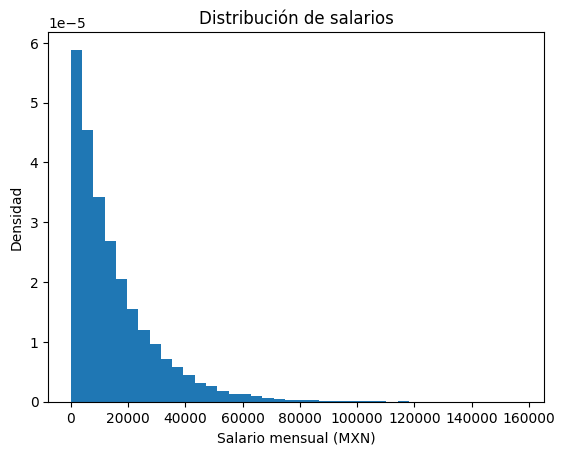

In [8]:
rng = np.random.default_rng(42)

N =  39_000           # Número de individuos
mu = 15000            # Salario promedio mensual (MXN)

salarios = rng.exponential(scale=mu, size=N)

plt.hist(salarios, bins=40, density=True)
plt.xlabel("Salario mensual (MXN)")
plt.ylabel("Densidad")
plt.title("Distribución de salarios")
plt.show()

In [24]:
np.random.shuffle(salarios)
salarios[0]

np.float64(7537.7176920946895)

In [26]:
# salarios = [np.random.normal(5,1) for _ in range(1000)]
# salarios = np.clip(salarios, 0, max(salarios))
# len(salarios), min(salarios), max(salarios)

agentes = []
np.random.shuffle(salarios)

for j in range(N):
    agente = A.Agente() # direccion requerida dummy
    sal = salarios[j]
    agente.salario = sal
    agentes.append(agente)

Creamos los agentes a partir del método que genera salarios con una distribución exponencial

In [42]:
# creamos los agentes con un método
# requiere del rng para generar números aleatorios
#
agentes = A.crea_agentes_exponencial(rng, N=N)
print(f"Generando {N} agentes {len(agentes)}")

Generando 39000 agentes 39000


Ancho de banda 159


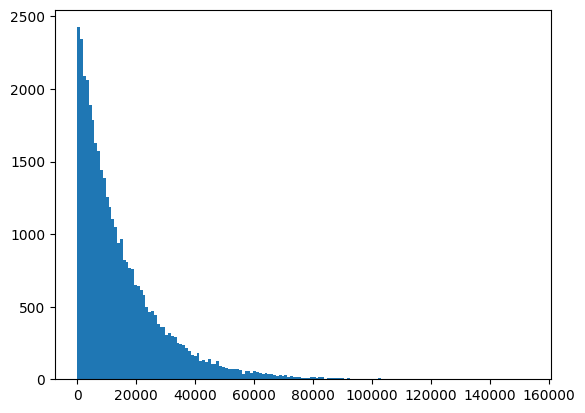

In [43]:
# comprobación de la distribución
salarios = np.array([ag.salario for ag in agentes])
bns = A.Obs.fd_bins(salarios)
print(f"Ancho de banda {bns}")
plt.hist(salarios, bins=bns);

## Vecindarios

Vamos a generar un vecindario con una distribución exponencial para los valores de la renta 

In [62]:
reload(A)

<module 'agentes_clase' from '/home/sergio/trabajo/phd/modelo_gentrificacion/agentes_clase.py'>

In [80]:
n = 50
params = {'tipo' : 'power_law', 'mu' : mu}

In [87]:
agentes = A.crea_agentes_exponencial(rng, N=2_500)

In [88]:
V = A.Vecindario(n=n,
                 k= 4, 
                 P=agentes,             # agentes recién creados
                 params=params, 
                 a = 0.1, 
                 b = 0.2,
                 pad=2)

Vamos a alojar a 2500 agentes


(array([1.633e+03, 5.240e+02, 2.140e+02, 7.900e+01, 3.000e+01, 1.200e+01,
        4.000e+00, 2.000e+00, 1.000e+00, 1.000e+00]),
 array([     0.        ,  13671.62767541,  27343.25535081,  41014.88302622,
         54686.51070163,  68358.13837703,  82029.76605244,  95701.39372784,
        109373.02140325, 123044.64907866, 136716.27675406]),
 <BarContainer object of 10 artists>)

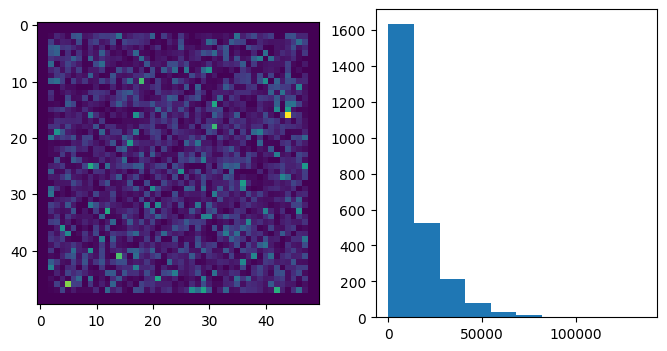

In [89]:
fig,ax = plt.subplots(1,2, figsize=(8,4))
ax[0].imshow(V.V)
ax[1].hist(V.V.flatten())

In [90]:
V.itera()

Las poblaciones C 1251 e I 1249


## Experimentos

In [ ]:
V, obs, bins_e = A.experimento(iters=10, p=2)